# **Analysis setup**

In [1]:
#| label: setup_packages_paths
#| code-fold: true
#| code-summary: "Setup: Imports and Reference File Paths"
#| output: false

# -------- data --------
import pyranges as pr
import pyfaidx                                  # FASTA indexing backend used by pr.get_sequence()
import pandas as pd
import numpy as np
from itables import init_notebook_mode, options, show
try:
    from itables import to_html_datatable
except ImportError:
    from itables.javascript import to_html_datatable

init_notebook_mode(all_interactive=True)

# -------- cmd / files / strings --------
import os
import re
import sys
import subprocess
import shutil
import tempfile
from pathlib import Path
from datetime import datetime
from urllib.parse import quote

# -------- graph --------
import matplotlib.pyplot as plt
from PIL import Image                          # reads the CIS-BP logo PNGs

# -------- display --------
from IPython.display import display, Markdown, HTML
import session_info

# -------- Setting the Path for the necessary files -------- #
# Everything is derived from PROJECT, so moving the project only changes one line.
# str() is used for the reference files because they are handed to pyranges/pyfaidx.

PROJECT = Path("/srv/ext_home/ssalazar/projects/GIMM_projects/DNA_018_PromotorSeq_MotifFinder")
DATA    = PROJECT / "Data"
RESULTS = PROJECT / "Results"
RESULTS.mkdir(parents=True, exist_ok=True)

SPECIES = "Mus musculus"
GENOME_ASSEMBLY = "GRCm39"
GENOME_ACCESSION = "GCF_000001635.27"
REFSEQ  = DATA / "ncbi_dataset_RefSeq_GCF_000001635.27"
GTF_v27 = str(REFSEQ / "genomic.gff")
FA_v27  = str(REFSEQ / "GCF_000001635.27_GRCm39_genomic.fna")

# written by the sequence-extraction cell, read back by every scan
PROMOTER_FASTA = RESULTS / "promoters_sequences.fasta"
RESULTS_FINAL_REPORT = RESULTS / "results_final_report"
RESULTS_FINAL_REPORT.mkdir(parents=True, exist_ok=True)
NOTEBOOK_NAME = "PromoterExtraction_adapted_with_rsatconda_refseqannotation.ipynb"
NOTEBOOK_CANDIDATES = (Path.cwd() / NOTEBOOK_NAME, Path.cwd() / "Notebooks" / NOTEBOOK_NAME,
                      *(parent / "Notebooks" / NOTEBOOK_NAME for parent in Path.cwd().parents))
NOTEBOOK_PATH = next((candidate.resolve() for candidate in NOTEBOOK_CANDIDATES if candidate.is_file()),
                     PROJECT / "Notebooks" / NOTEBOOK_NAME)
PROMOTER_FASTA_5kb = RESULTS / "promoters_sequences_5kb.fasta"



In [2]:
#| label: gtf_import
#| code-fold: true
#| code-summary: "Import and Filter Reference GTF"
#| output: false
# -------- Reference GTF -------- #
gtf = pr.read_gff3(GTF_v27)                           # Import the GTF file, which has all the information necessary to extract the coordinates. Keep all attributes in single string
gtf_canonical = gtf[(gtf.Feature == "mRNA") & 
                     gtf.tag.str.contains("RefSeq Select", na=False)] 
   # Filter to include only transcripts that contain the tag "RefSeq Select" (curated to canonical transcripts)

In [3]:
#| label: gene_subset
#| code-fold: true
#| code-summary: "Select Canonical Transcripts for Genes of Interest"
#| output: asis
# List of genes of interest

# Edit NETWORK_GENES to choose promoters for the motif scan.
NETWORK_GENES = [
    "Spic", "Nfe2l2", "Blvra", "Hmox1", "Vcam1", "Slc40a1", "Gsr",
    "Slc7a11", "Gclc", "Cat", "Gpx4", "Gclm", "Gss", "Txnrd1", "Fth1",
    "Nfs1", "Cisd1", "Aifm2", "Acsl4", "Acsl1", "Lpcat3", "G6pdx", "Pgd",
    "Me1", "Idh1", "Nox1", "Elovl7", "Ido1", "Alas1", "Dhodh", "Acsl3", "Scd1",
]
GENES_FOR_RETRIEVAL_ONLY = ["Bach1", "Scd5", "Nqo1"]
genes = list(dict.fromkeys(NETWORK_GENES + GENES_FOR_RETRIEVAL_ONLY))

PROMOTER_UPSTREAM_BP = 2000
PROMOTER_DOWNSTREAM_BP = 200
MARKOV_ORDER = 1
PVAL = 1e-4
CISBP = DATA / "Mus_musculus_2026_09_17_11_49_am_CISBP"
MOTIFS = {"M03221_3.10": "Spic",
          "M09222_3.10": "Nfe2l2_1",
          "M10174_3.10": "Nfe2l2_2",
          "M10181_3.10": "Bach1"}

# NCBI RefSeq GFF3 uses "gene", not "gene_name" -- confirm via gtf_canonical.columns.tolist()
# before trusting this line if it comes back empty.
gtf_sub = gtf_canonical[gtf_canonical.gene.isin(genes)]
 
found = set(gtf_sub.df["gene"])
missing = set(genes) - found
 
print(f"{len(found)}/{len(set(genes))} requested genes found among RefSeq Select transcripts")

if not missing:
    print("All requested genes were found.")


34/35 requested genes found among RefSeq Select transcripts


In [4]:
#| label: analysis_setup_summary
#| output: asis

# Motif labels are selected from the CIS-BP accession mapping above.
NETWORK_MOTIFS = list(MOTIFS.values())

motif_sources = ", ".join(
    f"{factor} ({accession})"
    for accession, factor in MOTIFS.items()
    if factor in NETWORK_MOTIFS
)
missing_text = (
    "Not found: " + ", ".join(
        f"[{gene}](https://www.uniprot.org/uniprotkb?query={quote(gene)})"
        for gene in sorted(missing)
    ) + ". Check UniProt for an alternate symbol, update the relevant gene list, and rerun."
    if missing else "All requested symbols were found among RefSeq Select records."
)

display(Markdown(
    f"**Organism/reference:** {SPECIES}, RefSeq {GENOME_ACCESSION} ({GENOME_ASSEMBLY}). "
    "Transcript coordinates use RefSeq Select records.\n\n"
    f"**Requested gene panel:** {len(set(genes))} symbols ({', '.join(genes)}); "
    f"{len(found)} found. {missing_text}\n\n"
    f"**Genes in this scan:** {len(NETWORK_GENES)} ({', '.join(NETWORK_GENES)}).\n\n"
    f"**TF motif matrices:** {motif_sources}. PWMs are loaded from the local "
    f"Mus musculus CIS-BP collection (`{CISBP.name}`) and scanned with RSAT.\n\n"
    f"**Promoter window:** -{PROMOTER_UPSTREAM_BP:,} bp upstream to "
    f"+{PROMOTER_DOWNSTREAM_BP:,} bp downstream of the TSS (strand-aware).\n\n"
    f"**Site threshold:** P < {PVAL:g}; background model: order-{MARKOV_ORDER} "
    "Markov model estimated from the promoters included in this scan."
))

**Organism/reference:** Mus musculus, RefSeq GCF_000001635.27 (GRCm39). Transcript coordinates use RefSeq Select records.

**Requested gene panel:** 35 symbols (Spic, Nfe2l2, Blvra, Hmox1, Vcam1, Slc40a1, Gsr, Slc7a11, Gclc, Cat, Gpx4, Gclm, Gss, Txnrd1, Fth1, Nfs1, Cisd1, Aifm2, Acsl4, Acsl1, Lpcat3, G6pdx, Pgd, Me1, Idh1, Nox1, Elovl7, Ido1, Alas1, Dhodh, Acsl3, Scd1, Bach1, Scd5, Nqo1); 34 found. Not found: [Scd5](https://www.uniprot.org/uniprotkb?query=Scd5). Check UniProt for an alternate symbol, update the relevant gene list, and rerun.

**Genes in this scan:** 32 (Spic, Nfe2l2, Blvra, Hmox1, Vcam1, Slc40a1, Gsr, Slc7a11, Gclc, Cat, Gpx4, Gclm, Gss, Txnrd1, Fth1, Nfs1, Cisd1, Aifm2, Acsl4, Acsl1, Lpcat3, G6pdx, Pgd, Me1, Idh1, Nox1, Elovl7, Ido1, Alas1, Dhodh, Acsl3, Scd1).

**TF motif matrices:** Spic (M03221_3.10), Nfe2l2_1 (M09222_3.10), Nfe2l2_2 (M10174_3.10), Bach1 (M10181_3.10). PWMs are loaded from the local Mus musculus CIS-BP collection (`Mus_musculus_2026_09_17_11_49_am_CISBP`) and scanned with RSAT.

**Promoter window:** -2,000 bp upstream to +200 bp downstream of the TSS (strand-aware).

**Site threshold:** P < 0.0001; background model: order-1 Markov model estimated from the promoters included in this scan.

In [5]:
#| label: gene_promoter_coordinates
#| code-fold: true
#| code-summary: "Gene and promoter coordinates"
#| output: asis

prom_2kb = gtf_sub.five_end().slack({"5": PROMOTER_UPSTREAM_BP, "3": PROMOTER_DOWNSTREAM_BP})

gene_promoter_coordinates = (
    gtf_sub.df[["Chromosome", "gene", "transcript_id", "Strand", "Start", "End"]]
    .rename(columns={"Start": "gene_start", "End": "gene_end"})
    .merge(
        prom_2kb.df[["gene", "transcript_id", "Start", "End"]]
        .rename(columns={"Start": "promoter_start", "End": "promoter_end"}),
        on=["gene", "transcript_id"],
        how="left",
    )
)
gene_promoter_coordinates["start_to_end_gene"] = (
    gene_promoter_coordinates["gene_start"].astype(str)
    + " - "
    + gene_promoter_coordinates["gene_end"].astype(str)
)
gene_promoter_coordinates["start_to_end_promoter"] = (
    gene_promoter_coordinates["promoter_start"].astype(str)
    + " - "
    + gene_promoter_coordinates["promoter_end"].astype(str)
)
gene_promoter_coordinates = gene_promoter_coordinates[
    ["Chromosome", "gene", "transcript_id", "Strand", "start_to_end_gene", "start_to_end_promoter"]
]
gene_promoter_coordinates.to_csv(RESULTS_FINAL_REPORT / "gene_promoter_coordinates.csv", index=False)
display(Markdown("Each row lists a selected transcript and its genomic and promoter coordinates."))
show(gene_promoter_coordinates, allow_html=True)

Each row lists a selected transcript and its genomic and promoter coordinates.

Loading ITables v2.6.1 from the init_notebook_mode cell... (need help?)


In [6]:
#| label: extract_sequences
#| code-fold: true
#| code-summary: "Extract Promoter Sequences from Reference"
#| output: false

seqs_2kb = pr.get_sequence(prom_2kb, path=FA_v27)                        # Based on the coordinates identified before, we get the sequences from the reference genome
#get_sequence is also strand-aware and reverse-complements the minus strand

df_2kb                 = seqs_2kb.to_frame(name="DNA_Sequence")   # Convert the extracted sequences into a dataframe
df_2kb["Gene_Name"]    = prom_2kb.df['gene']                 # Attach gene names for use in the FASTA headers
df_2kb["TranscriptID"] = prom_2kb.df["transcript_id"]             # Attach transcript IDs for use in the FASTA headers

with open(PROMOTER_FASTA, "w") as file:
    for index, row in df_2kb.iterrows():
        # Combine your metadata into a single header line
        header = f">{row['Gene_Name']}|{row['TranscriptID']}"
        
        # Write the header and the sequence
        file.write(f"{header}\n")
        file.write(f"{row['DNA_Sequence']}\n")

In [7]:
#| label: rsat_setup
#| code-fold: true
#| code-summary: "Setup: paths and scan parameters"
#| output: false
 
# paths and variables
 
SCAN_DIR = RESULTS / "matrix_scan"
SCAN_DIR.mkdir(parents=True, exist_ok=True)
RSAT_ENV = Path("/srv/ext_home/ssalazar/.conda/envs/rsat")
 
TSS_OFFSET   = 201      # -origin end places the TSS at -201
 
# rsat is a Perl script: its env's bin must lead PATH, or the shebang picks base's perl
ENV = os.environ | {"PATH": f"{RSAT_ENV / 'bin'}{os.pathsep}{os.environ['PATH']}",
                     "RSAT": str(RSAT_ENV / 'share' / 'rsat'),
                     "CONDA_PREFIX": str(RSAT_ENV)}
 
 
def rsat(tool, *args):
    # some tools report errors on stdout while exiting 0
    cmd = [str(RSAT_ENV / "bin" / "rsat"), tool, *map(str, args)]
    p = subprocess.run(cmd, capture_output=True, text=True, env=ENV)
    out = p.stderr + p.stdout
    if p.returncode or re.search(r"^Error", out, re.M):
        raise RuntimeError(" ".join(cmd) + "\n" + out)
    return out
 
 
def read_fasta(path):
    # [(header, sequence), ...], headers keep their '>'
    # used for counting/subsetting only, so no Biopython dependency;
    # `cur is not None` (not `cur`) so a header right after another header
    # doesn't swallow the next record's lines
    recs, cur = [], None
    for line in Path(path).read_text().splitlines():
        if line.startswith(">"):
            cur = [line, []]
            recs.append(cur)
        elif cur is not None:
            cur[1].append(line.strip())
    return [(h, "".join(s)) for h, s in recs]
 
 

These sequence logos show the CIS-BP motifs scanned, in forward and reverse orientations.

  M03221_3.10    14 bp -> Spic


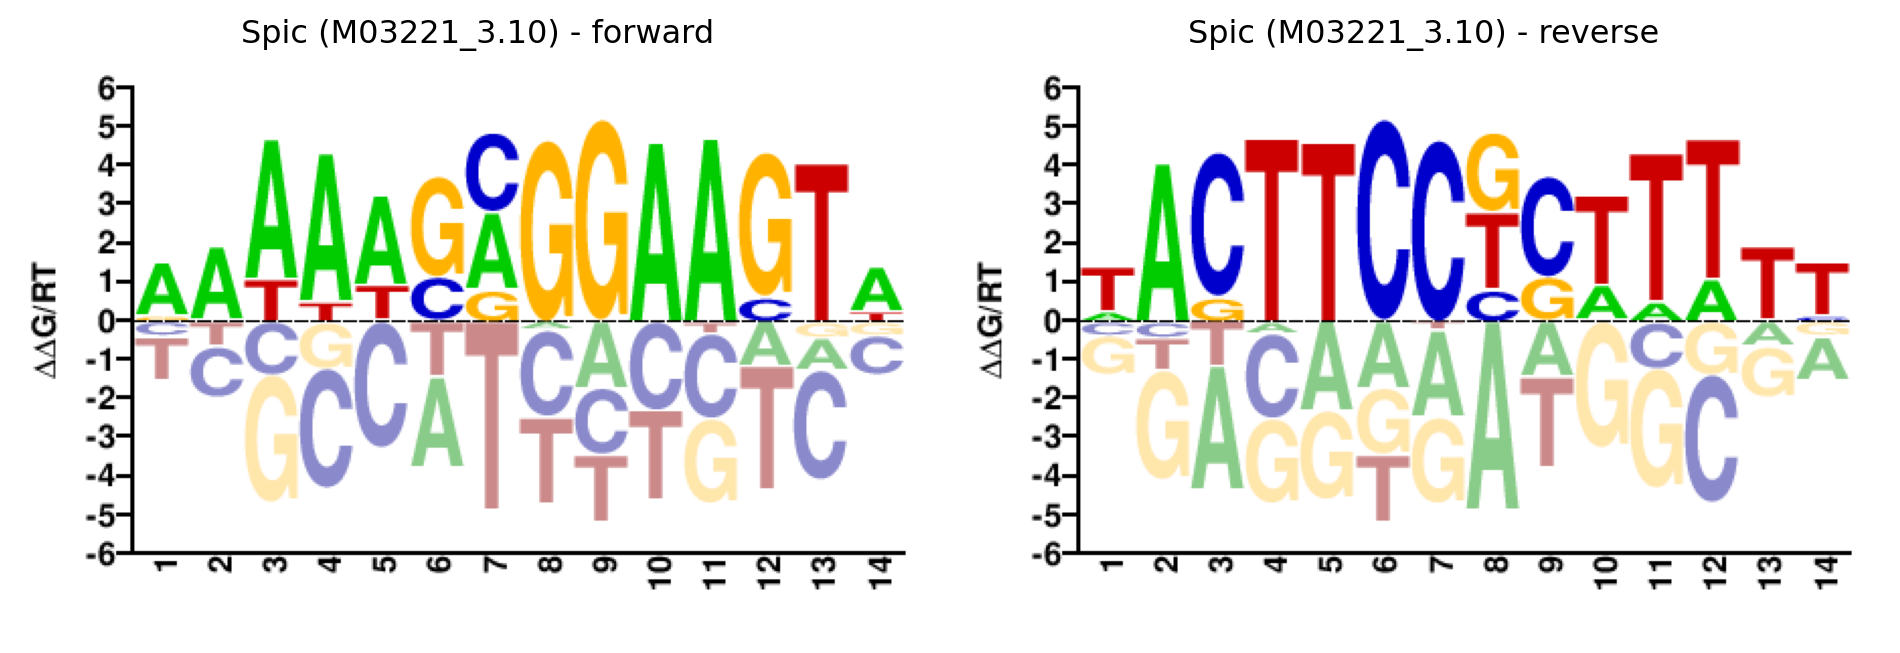

  M09222_3.10    11 bp -> Nfe2l2_1


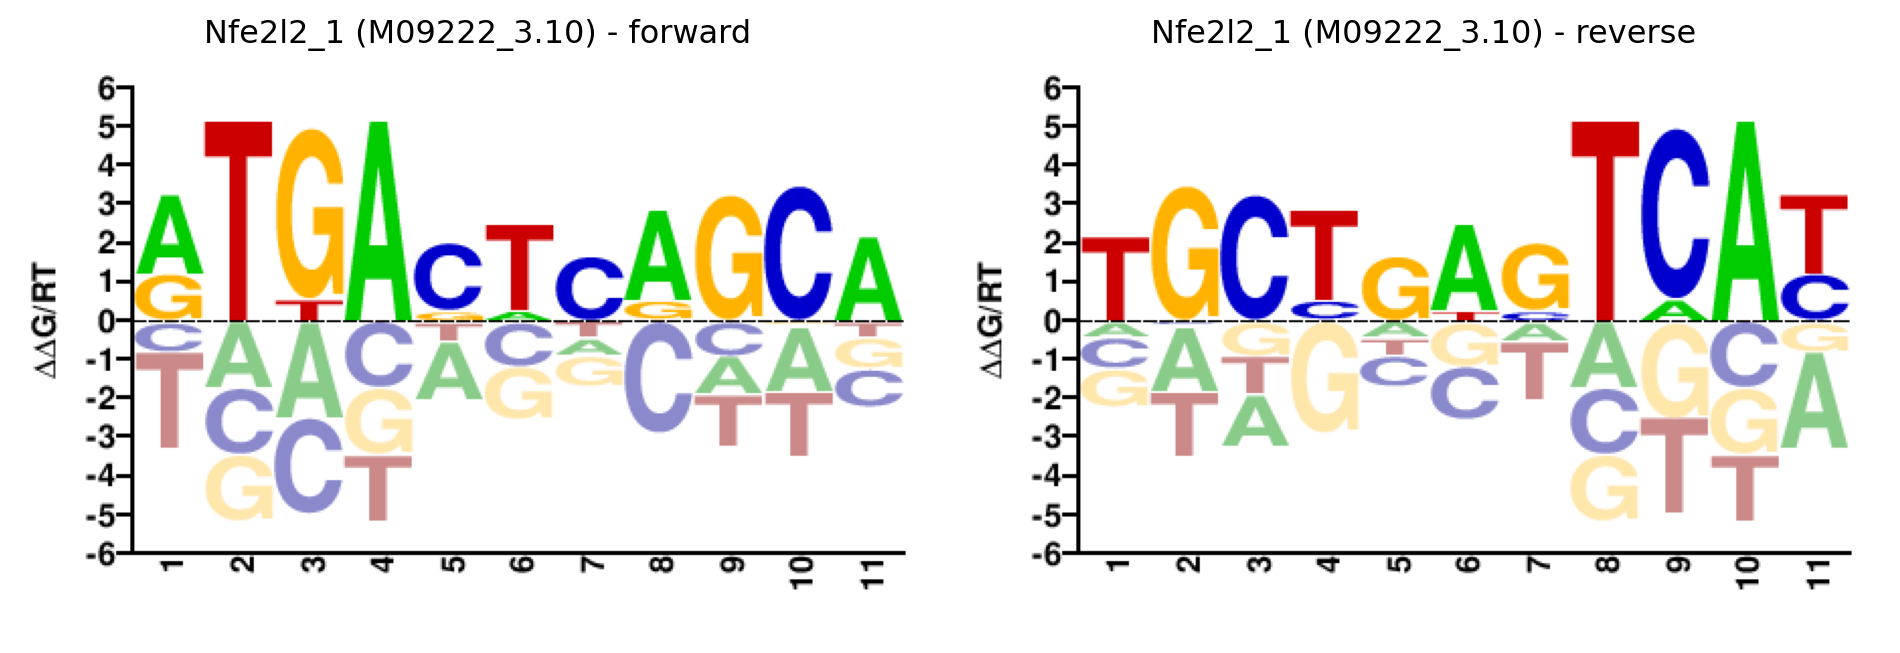

  M10174_3.10    14 bp -> Nfe2l2_2


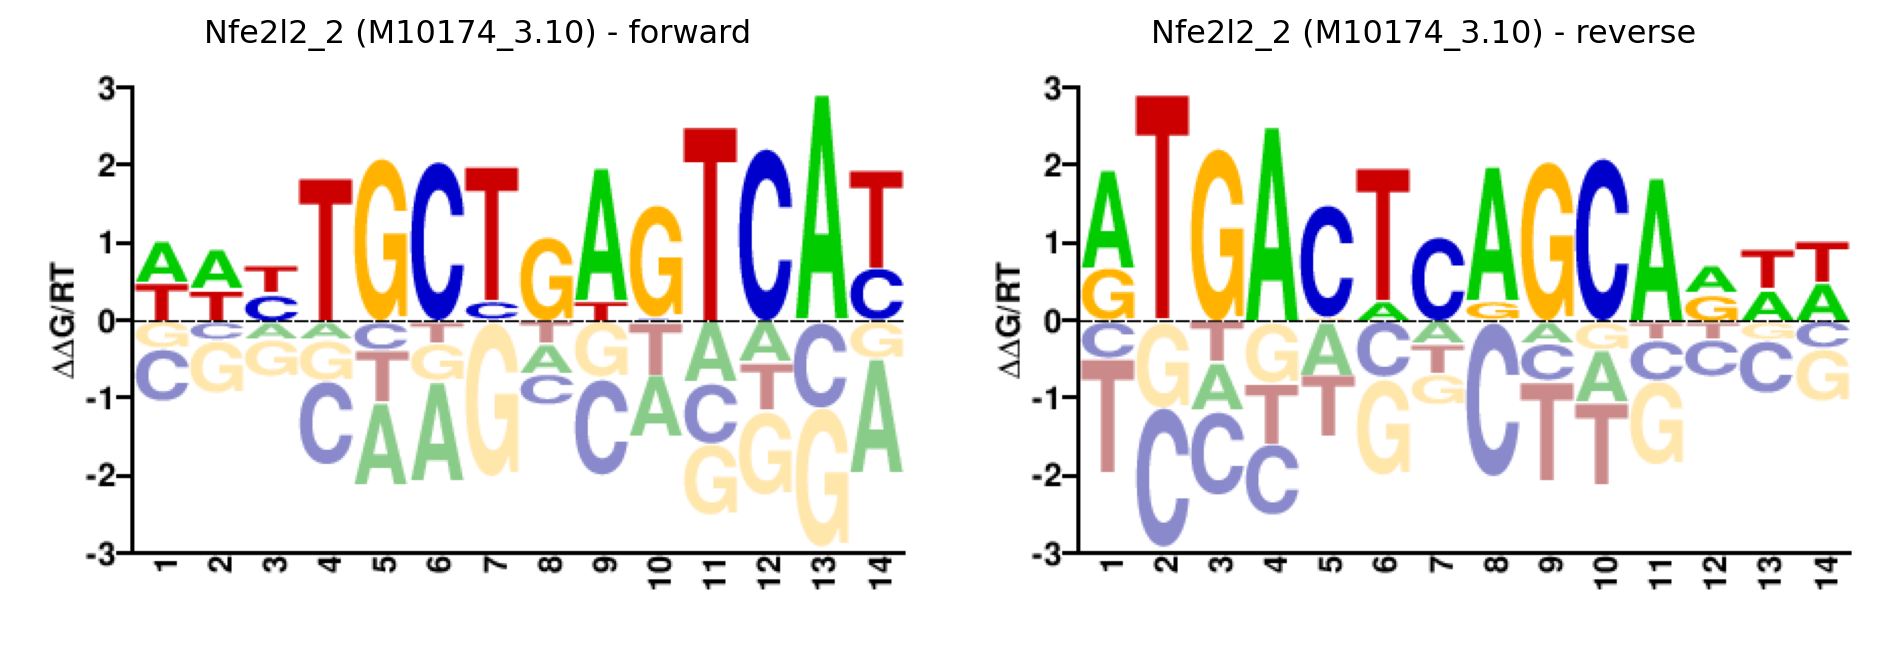

  M10181_3.10    14 bp -> Bach1


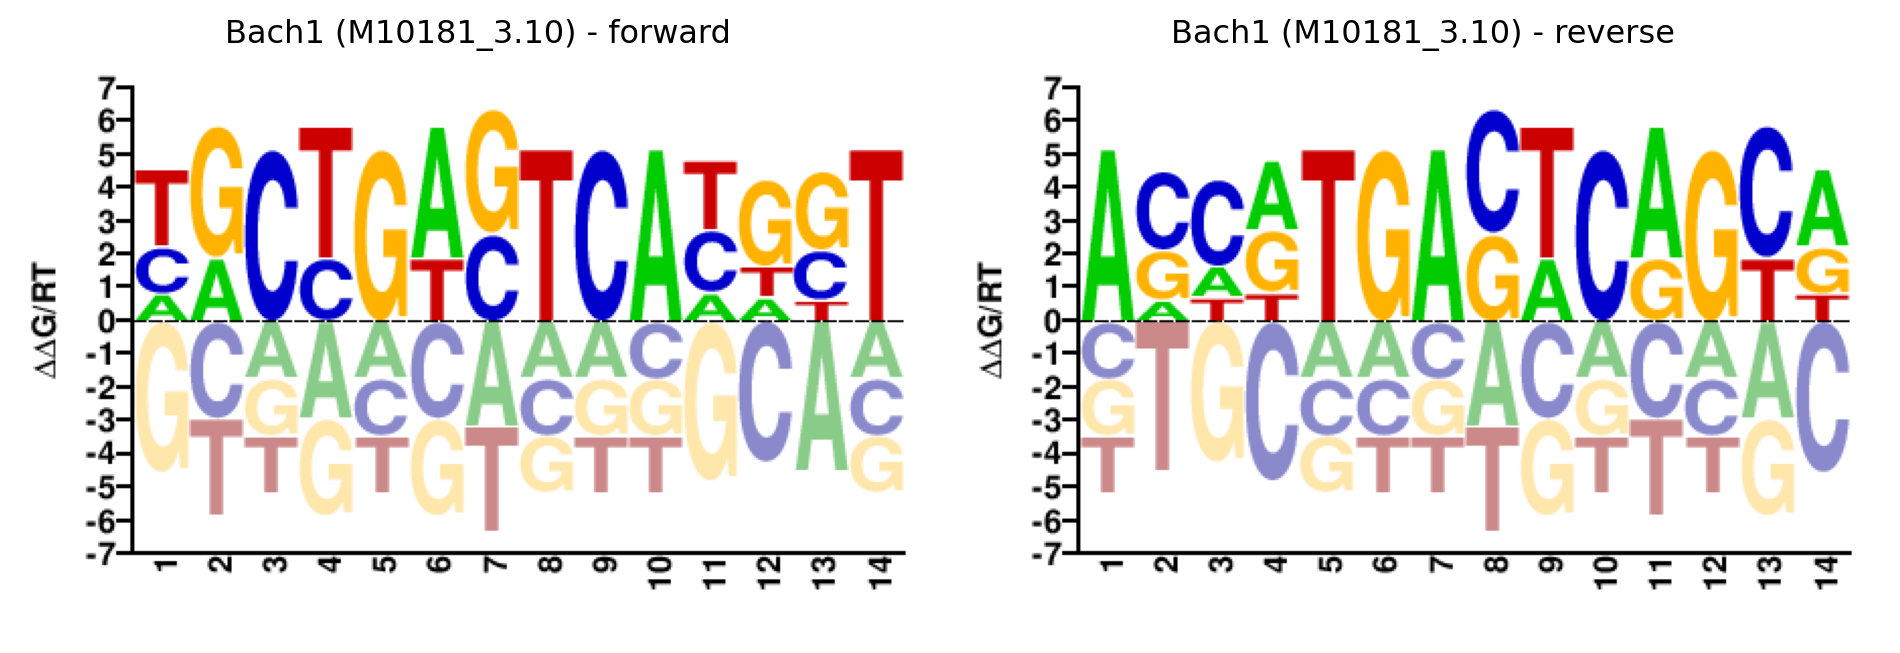


4 matrices saved in motif_matrices_SpiC_Nfe2l2_Bach1.tf


In [8]:
#| label: tf_matrices
#| code-fold: true
#| code-summary: "transcription factor matrices"
#| output: asis
 
# color dictionary for consistency across plots (npg / Nature Publishing Group palette)
MOTIF_COLORS = {"Spic":     "#E64B35",
                 "Nfe2l2_1": "#4DBBD5",
                 "Nfe2l2_2": "#00A087",
                 "Bach1":    "#3C5488"}

display(Markdown("These sequence logos show the CIS-BP motifs scanned, in forward and reverse orientations."))
blocks = []
for acc, label in MOTIFS.items():
    m = pd.read_csv(CISBP / "pwms_all_motifs" / f"{acc}.txt", sep="\t")
 
    # CIS-BP gives probabilities (rows sum to 1); x100 makes them count-like, so
    # matrix-scan's -pseudo 1 stays a small correction instead of half the column
    rows = [f"{i:02d}\t" + "\t".join(f"{v * 100:.4f}" for v in r)
            for i, r in enumerate(m[["A", "C", "G", "T"]].values, start=1)]
 
    blocks.append(f"AC  {acc}\nXX\nID  {label}\nXX\nDE  {label}\n"
                   "P0\tA\tC\tG\tT\n" + "\n".join(rows) + "\nXX\n//\n")
    print(f"  {acc:<14} {len(m)} bp -> {label}")

    # Show the CIS-BP logo of the matrix actually scanned, both orientations, so the
    # report records what each matrix looks like and not only its accession.
    ifw  = Image.open(CISBP / "logos_used_motifs" / f"{acc}_fwd.png")
    irev = Image.open(CISBP / "logos_used_motifs" / f"{acc}_rev.png")

    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    axes[0].imshow(ifw)
    axes[0].set_title(f"{label} ({acc}) - forward")
    axes[0].axis("off")
    axes[1].imshow(irev)
    axes[1].set_title(f"{label} ({acc}) - reverse")
    axes[1].axis("off")
    plt.tight_layout()
    fig.savefig(SCAN_DIR / f"motif_logo_{label}.svg", format="svg", bbox_inches="tight")
    plt.show()
 
MATRIX = SCAN_DIR / "motif_matrices_SpiC_Nfe2l2_Bach1.tf"
MATRIX.write_text("".join(blocks))
print(f"\n{len(blocks)} matrices saved in {MATRIX.name}")

In [9]:
#| label: rsat_scan
#| code-fold: true
#| code-summary: "Motif scan function"
#| output: false
 
def scan(motifs, genes=None, pval=PVAL, name=None, bg_from="input", MATRIX = MATRIX, FASTA=None):
    # motifs: list of ft_name labels, e.g. ['Spic', 'Bach1']
    # genes: list of gene names; None scans all promoters
    # only the .ft.txt is kept

    out = SCAN_DIR / f"scanmotif_{name}.ft"

    # matrix subset, promoter subset and background model are RSAT inputs, so they're
    # written to a temp dir removed on return; still recoverable from the ';' header of
    # the .ft.txt, which records the matrix, pseudo-counts and residue probabilities
    with tempfile.TemporaryDirectory() as tmp:
        tmp = Path(tmp)
 
        # requested matrices only, from motif_matrices_SpiC_Nfe2l2_Bach1.tf
        blocks = [b.strip() + "\n//\n" for b in MATRIX.read_text().split("//")
                  if (m := re.search(r"^ID\s+(\S+)\s*$", b, re.M))
                  and m.group(1) in motifs]
        assert len(blocks) == len(motifs), f"matrix not found, wanted {motifs}"
        mat = tmp / "matrices.tf"
        mat.write_text("".join(blocks))
 
        # requested promoters only; genes=None keeps all
        recs = [(i, s) for i, s in read_fasta(FASTA)
                if not genes or any(g.lower() in i.lower() for g in genes)]
        assert recs, f"no promoter matched {genes}"
        seqs = tmp / "promoters.fasta"
        seqs.write_text("".join(f">{i}\n{s}\n" for i, s in recs))
 
        # background is always estimated from the FULL promoter set, never the gene
        # -bginput / create-background-model fail in this build (rsat-core 2025.04.04,
        # bioconda) at every Markov order ("the sum must be strictly positive", then a
        # division by zero in RSAT/matrix.pm), so the model is estimated with
        # oligo-analysis and passed via -bgfile instead: same estimator, same sequences.
        # -1str matches the web run, whose residue probabilities are strand-asymmetric.
        # verified against the web run: 62/63 sites, same 20 promoters, marginals to 3 decimals
        bg = tmp / "bg.tab"
        bg_src = FASTA if bg_from == "all" else seqs
        rsat("oligo-analysis", "-i", bg_src, "-l", MARKOV_ORDER + 1, "-1str",
             "-return", "occ,freq", "-o", bg)
 
        # -origin end keeps positions negative from the sequence end (TSS at -TSS_OFFSET)
        # -2str reports D/R, combined with transcript strand downstream
        # -return limits gives the START_END rows used for promoter extents
        rsat("matrix-scan", "-v", 1,
             "-i", seqs, "-seq_format", "fasta",
             "-m", mat, "-matrix_format", "transfac",
             "-bgfile", bg, "-bg_pseudo", 0.01, "-pseudo", 1,
             "-2str", "-origin", "end", "-n", "score",
             "-return", "limits", "-return", "sites", "-return", "pval",
             "-uth", "pval", pval, "-o", out)
 
    hits = pd.read_csv(out, sep="\t", comment=";").query("ft_type == 'site'")
    hits.attrs["scan_path"] = out
    print(f"{len(recs)} promoters, {len(motifs)} matrices, "
          f"{len(hits)} sites at P < {pval:g}")
   
    return hits

In [10]:
#| label: sitemap_function
#| code-fold: true
#| code-summary: "Site map function"
#| output: false

def sitemap(hits, name=None, pval=PVAL, MOTIF_COLORS = MOTIF_COLORS):
    """Map motif sites along each promoter, positions relative to the TSS.

    hits  the DataFrame returned by scan(); its .attrs['scan_path'] is re-read to
          recover the 'limit' rows, so promoters with no site still get a lane.
    """
    
    path = Path(hits.attrs["scan_path"])
    lim  = (pd.read_csv(path, sep="\t", comment=";").query("ft_type == 'limit'")
              .drop_duplicates("#seq_id").set_index("#seq_id"))

    h = hits.assign(tss_pos=hits[["start", "end"]].mean(axis=1) + TSS_OFFSET,
                    logp=-np.log10(hits["Pval"]))
    ypos   = {s: i for i, s in enumerate(lim.index)}
    colors = {m: MOTIF_COLORS.get(m, "0.4") for m in h["ft_name"].unique()}

    fig, ax = plt.subplots(figsize=(9, 0.33 * len(lim) + 1.5))
    ax.hlines(range(len(lim)), lim["start"] + TSS_OFFSET, lim["end"] + TSS_OFFSET,
              color="0.87", lw=3.5, zorder=1)

    # Size scales with significance from the threshold up; label once per motif,
    # on the direct strand, so the legend shows colour rather than colour x strand.
    for (motif, strand), g in h.groupby(["ft_name", "strand"]):
        ax.scatter(g["tss_pos"], g["#seq_id"].map(ypos),
                   marker="v" if strand == "R" else "^",
                   s=50 + 200 * (g["logp"] + np.log10(pval)) / 3,
                   color=colors[motif], zorder=3, alpha=0.85,
                   edgecolors="white", linewidths=0.4,
                   label=motif if strand == "D" else None)

    ax.axvline(0, color="crimson", lw=1, ls="--", zorder=2)
    ax.text(0, -0.65, " TSS", color="crimson", va="top", fontsize=8)
    ax.set_yticks(range(len(lim)))
    ax.set_yticklabels([s.lstrip(">").split("|")[0] for s in lim.index], fontsize=10)
    ax.set_ylim(-0.7, len(lim) - 0.3); ax.invert_yaxis()
    ax.set_xlabel("position relative to TSS (bp)")
    ax.legend(title=f"motif (P < {pval:g})", fontsize=10, title_fontsize=10,
              markerscale=0.8, loc="upper left", bbox_to_anchor=(1.01, 1),
              frameon=False)
    ax.spines[["top", "right", "left"]].set_visible(False)
    fig.tight_layout(rect=[0, 0, 0.85, 1])

    fig_path = SCAN_DIR / f"sitemap_{name}.svg"
    fig.savefig(fig_path)
  
    return fig

In [11]:
#| label: process_motif_hits
#| code-fold: true
#| code-summary: "Process motif hits"
#| output: false

def process_motif_hits(name, hits_df, gtf_sub):

        # prepare data from RSAT tools
        sites = hits_df[hits_df["ft_type"] == "site"].copy()   # drop the 'limit' (START_END) rows, not significant
        sites[["Gene_Name", "TranscriptID"]] = sites["#seq_id"].str.split("|", expand=True)  # seq_id = Gene_Name|TranscriptID
        sites["Gene_Name"] = sites["Gene_Name"].str.strip('>')

        sites_filtered = sites[['Gene_Name', 'TranscriptID', 'sequence', 'start', 'end', 'strand', 'Pval', 'sig']].copy()
        sites_filtered = sites_filtered.rename(columns={'sequence': 'Motif_Sequence_Found',
                                                        'start':   "start_motif_pos_promoter",   # 1-based TSS base
                                                        'end':     "end_motif_pos_promoter",
                                                        'strand':  "strand_motif"})

        # get transcript metadata + TSS (from five_end(), 1-based, strand dependent), merge in one go
        meta = (gtf_sub.df[["Chromosome", "Strand", "transcript_id"]]
                .rename(columns={"Strand": "Chromosome_Strand", "transcript_id": "TranscriptID"})
                .merge(gtf_sub.five_end().df[["transcript_id", "End"]]
                        .rename(columns={"End": "TSS_chromosomal_localization", "transcript_id": "TranscriptID"}),
                        on="TranscriptID", how="left"))

        sites_filtered = sites_filtered.merge(meta, on="TranscriptID", how="left")

        # transcript-relative edges: 0 = TSS base, + = downstream (origin=end anchor at -201)
        sites_filtered["start_motif_pos_promoter"] += TSS_OFFSET
        sites_filtered["end_motif_pos_promoter"]   += TSS_OFFSET

        # nearest edge: end if upstream, start if downstream, 0 if it straddles the TSS
        sites_filtered["dist_to_TSS"] = np.where(
        sites_filtered["end_motif_pos_promoter"] < 0, sites_filtered["end_motif_pos_promoter"],
        np.where(sites_filtered["start_motif_pos_promoter"] > 0, sites_filtered["start_motif_pos_promoter"], 0),
        )

        # to genome (1-based): + adds, - subtracts (edges swap so start <= end)
        plus = sites_filtered["Chromosome_Strand"].eq("+")
        TSS  = sites_filtered["TSS_chromosomal_localization"]
        start = np.where(plus, TSS + sites_filtered["start_motif_pos_promoter"], TSS - sites_filtered["end_motif_pos_promoter"])
        end   = np.where(plus, TSS + sites_filtered["end_motif_pos_promoter"],   TSS - sites_filtered["start_motif_pos_promoter"])

        sites_filtered["motif_genomic_localization"] = start.astype(int).astype(str) + "-" + end.astype(int).astype(str)
        sites_filtered["motif_genomic_strand"] = np.where(plus == sites_filtered["strand_motif"].eq("D"), "+", "-")

        sites_filtered.drop(columns=["strand_motif"], inplace=True)

        sites_filtered.to_csv(RESULTS / f"motifs_coordinates_{name}.csv", index=False)
        return sites_filtered

## Motif scan results

32 promoters, 4 matrices, 93 sites at P < 0.0001


This map shows the scanned promoter regions and detected motif sites relative to each transcription start site.

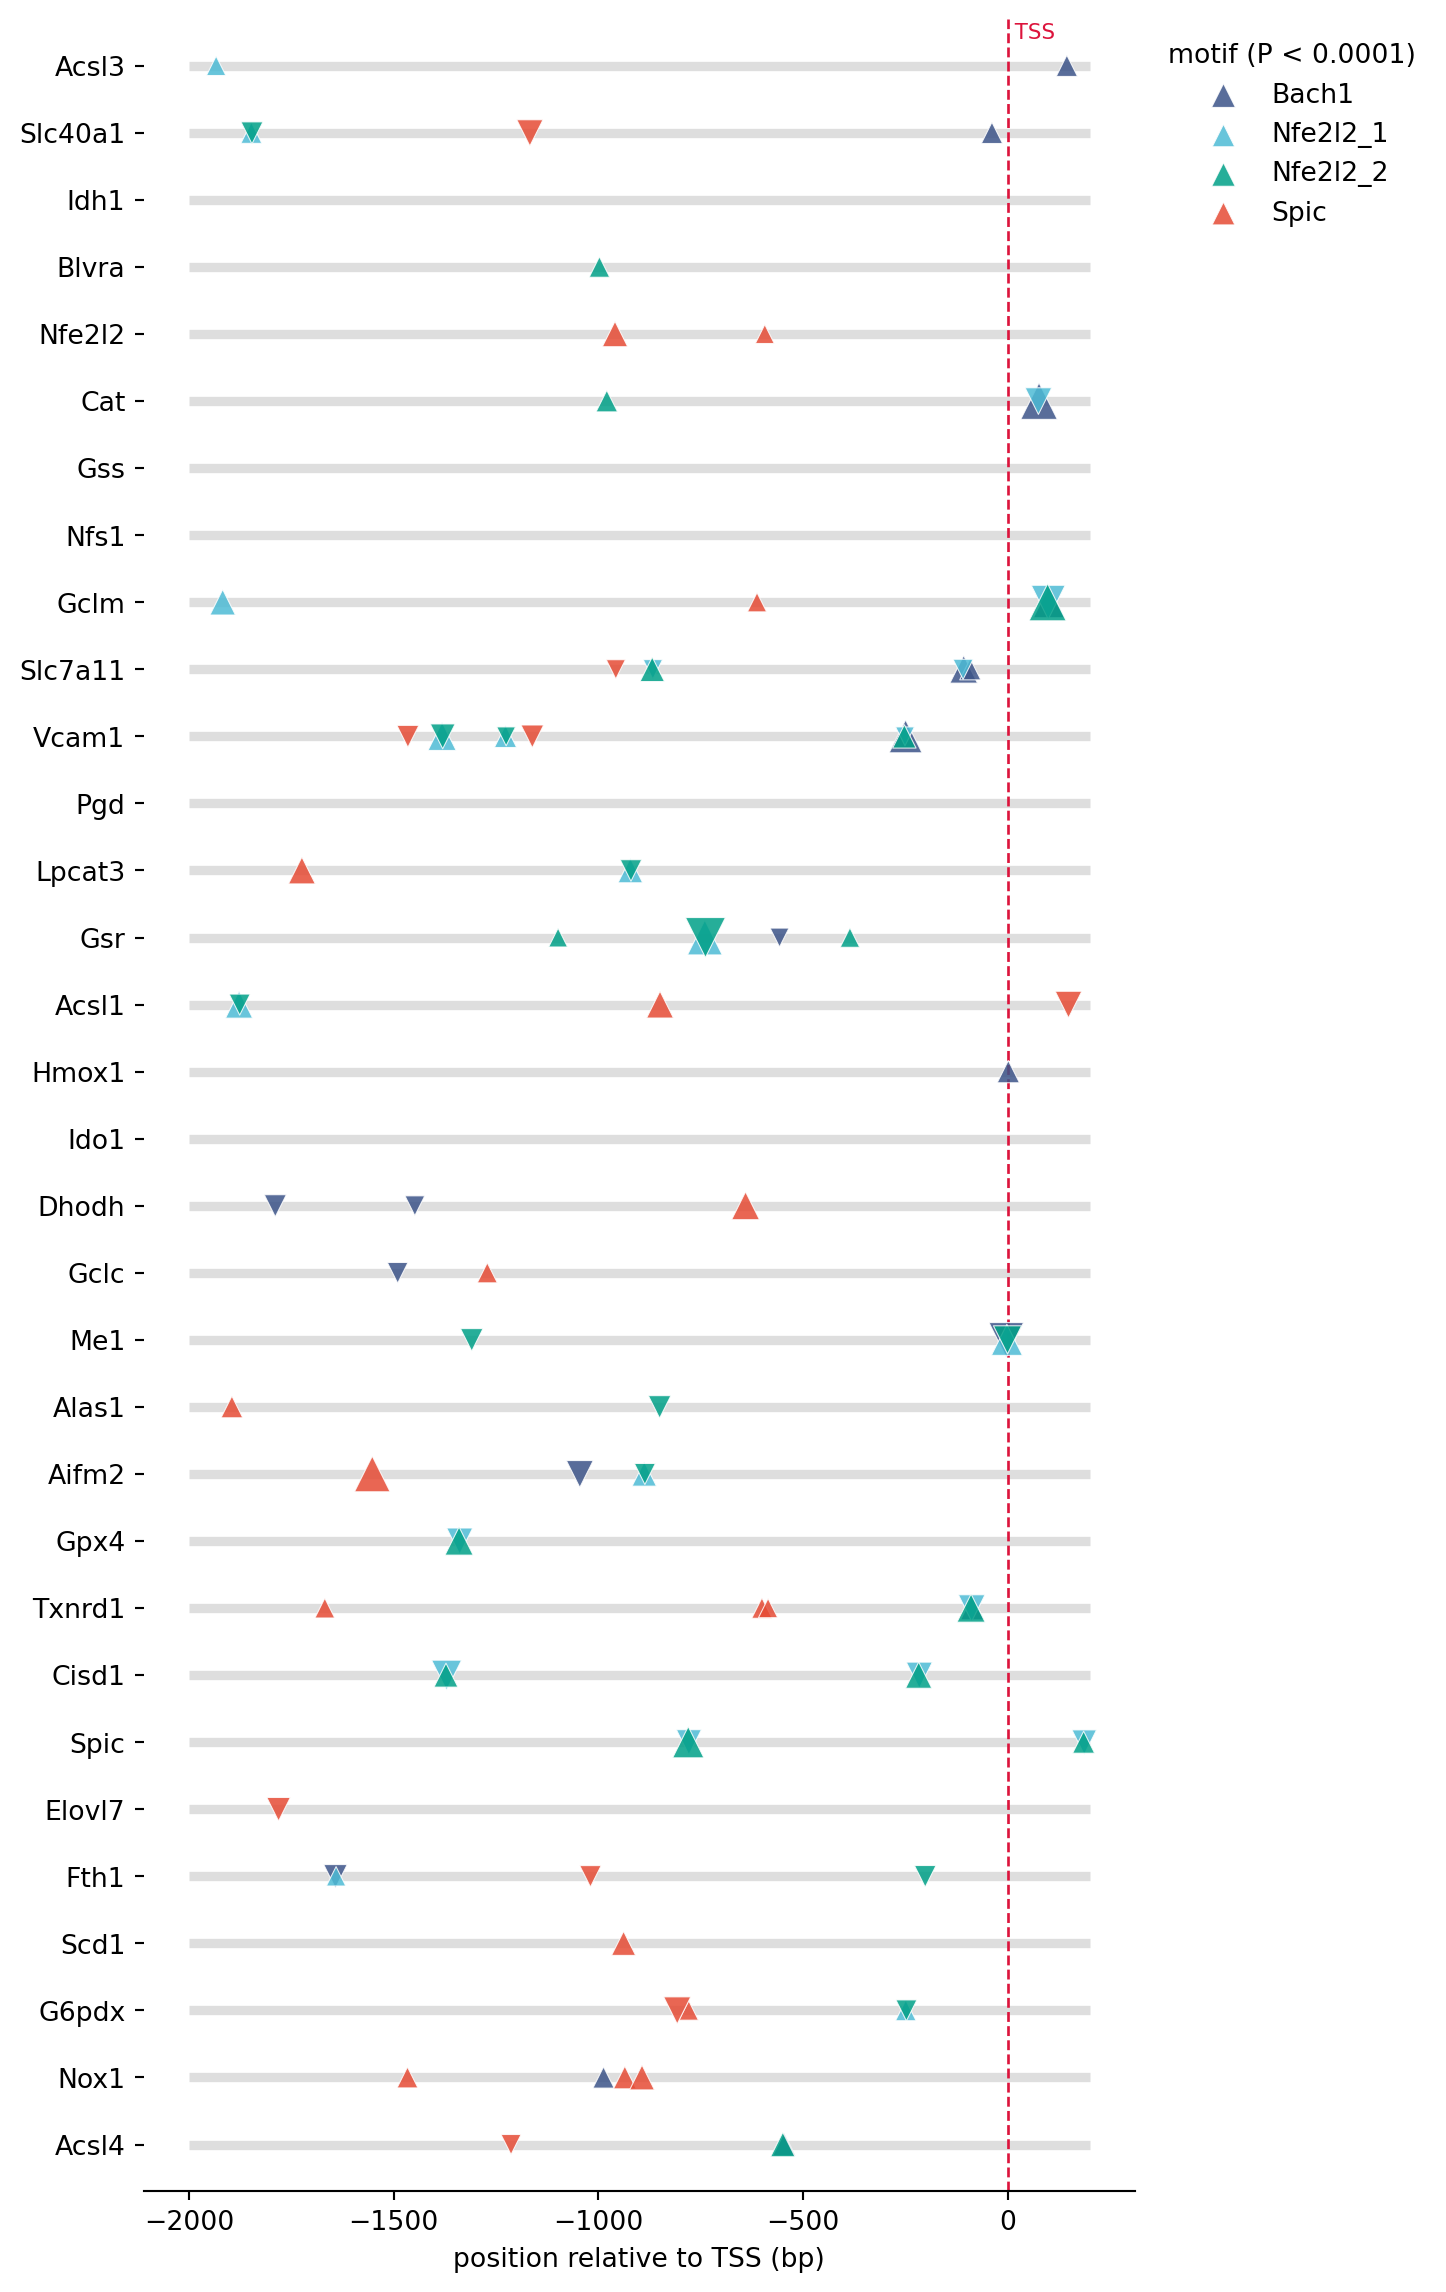

In [12]:
#| label: regulation_interaction_map
#| code-fold: true
#| code-summary: "Regulation Map"
#| output: asis
#| column: page

hits_SpiCnet_allmotifs = scan(NETWORK_MOTIFS, genes=NETWORK_GENES, name="SpiC_network_all_TFs", FASTA=PROMOTER_FASTA)

graph_SpiCnet_allmotifs = sitemap(hits_SpiCnet_allmotifs, name="SpiC_network_all_TFs")

display(Markdown("This map shows the scanned promoter regions and detected motif sites relative to each transcription start site."))
display(graph_SpiCnet_allmotifs)
plt.close(graph_SpiCnet_allmotifs)
_ = shutil.copy2(
    SCAN_DIR / "sitemap_SpiC_network_all_TFs.svg",
    RESULTS_FINAL_REPORT / "sitemap_SpiC_network_all_TFs.svg",
)


In [13]:
#| label: spicnetwork_alltfs_motifs_table
#| code-fold: true
#| code-summary: "SpiC Network SpiC, Nfe2l2 and Bach1 Motifs Table"
#| output: asis

spicnet_allmotifs_table = process_motif_hits("SpiC_network_all_TFs", hits_SpiCnet_allmotifs, gtf_sub)
motif_hits_path = RESULTS / "motifs_coordinates_SpiC_network_all_TFs.csv"
shutil.copy2(motif_hits_path, RESULTS_FINAL_REPORT / motif_hits_path.name)
display(Markdown("Each row reports a detected motif site with its sequence, promoter position, and significance."))
show(spicnet_allmotifs_table, allow_html=True)

Each row reports a detected motif site with its sequence, promoter position, and significance.

Loading ITables v2.6.1 from the init_notebook_mode cell... (need help?)


In [14]:
#| label: render_report
#| echo: false
#| eval: false
#| output: false
#| code-summary: "Render and package the final report"

os.environ["QUARTO_PYTHON"] = sys.executable
output_dir = os.path.relpath(RESULTS_FINAL_REPORT, NOTEBOOK_PATH.parent)
render_status = os.system(
    f'cd "{NOTEBOOK_PATH.parent}" && quarto render "{NOTEBOOK_PATH.name}" '
    f'--to html --execute --no-clean --output-dir "{output_dir}"'
)
if render_status != 0:
    raise RuntimeError(f"Quarto render failed with exit status {render_status}")

report_path = RESULTS_FINAL_REPORT / f"{NOTEBOOK_PATH.stem}_report.html"
os.rename(RESULTS_FINAL_REPORT / NOTEBOOK_PATH.with_suffix(".html").name, report_path)
zip_path = shutil.make_archive(
    str(RESULTS / f"results_final_report_{datetime.now():%Y%m%d_%H%M}"),
    "zip",
    root_dir=RESULTS_FINAL_REPORT,
)
print(f"Report: {report_path}")
print(f"Archive: {zip_path}")